In [1]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

Zgrupować tabele po zmiennej symbolicznej Y , a następnie wyznaczyć średnią wartość atrybutu numerycznego X w grupach wyznaczonych przez Y.

In [57]:
df = pd.DataFrame({'x': [1, 2, 3, 4, 5], 'y': ['a', 'b', 'a', 'b', 'b']})
print(df)
print(df.groupby('y').mean())

   x  y
0  1  a
1  2  b
2  3  a
3  4  b
4  5  b
          x
y          
a  2.000000
b  3.666667


Wyznaczyć rozkład liczności atrybutów (value counts).

In [58]:
print(df['x'].value_counts())
print(df['y'].value_counts())

x
1    1
2    1
3    1
4    1
5    1
Name: count, dtype: int64
y
b    3
a    2
Name: count, dtype: int64


Wyczytać dane autos.csv, za pomocą polecenia np.loadtxt oraz pandas.read csv. Sprawdź różnice.

In [59]:
txt = np.loadtxt('autos.csv', dtype=str)
data = pd.read_csv('autos.csv')
# print(txt)
print(data)

     Unnamed: 0  normalized-losses         make fuel-type aspiration  \
0             0                NaN  alfa-romero       gas        std   
1             1                NaN  alfa-romero       gas        std   
2             2                NaN  alfa-romero       gas        std   
3             3              164.0         audi       gas        std   
4             4              164.0         audi       gas        std   
..          ...                ...          ...       ...        ...   
200         200               95.0        volvo       gas        std   
201         201               95.0        volvo       gas      turbo   
202         202               95.0        volvo       gas        std   
203         203               95.0        volvo    diesel      turbo   
204         204               95.0        volvo       gas      turbo   

    num-of-doors   body-style drive-wheels engine-location  wheel-base  ...  \
0            two  convertible          rwd           fro

np.loadtxt('autos.csv', dtype=str) wczytuje wszystkie dane w postacji stringów
data = pd.read_csv('autos.csv') stara się dopasowac odpowiednie typy danych

Zgrupować ramkę danych po zmiennej 'make' a następnie wyznaczyć średnie zużycie paliwa dla każdego z producentów.

In [60]:
# print(data.columns)
print(data.groupby('make')[['city-mpg', 'highway-mpg']].mean().mean(axis=1))

make
alfa-romero      23.500000
audi             21.500000
bmw              22.375000
chevrolet        43.666667
dodge            31.055556
honda            32.923077
isuzu            33.500000
jaguar           16.333333
mazda            28.823529
mercedes-benz    19.750000
mercury          21.500000
mitsubishi       28.038462
nissan           29.972222
peugot           24.545455
plymouth         31.142857
porsche          21.700000
renault          27.000000
saa              23.833333
subaru           28.541667
toyota           30.203125
volkswagen       31.750000
volvo            23.500000
dtype: float64


Zgrupować ramkę danych po zmiennej make liczności dla atrybutu fuel-type.

In [61]:
print(data.groupby('make')['fuel-type'].value_counts())

make           fuel-type
alfa-romero    gas           3
audi           gas           7
bmw            gas           8
chevrolet      gas           3
dodge          gas           9
honda          gas          13
isuzu          gas           4
jaguar         gas           3
mazda          gas          15
               diesel        2
mercedes-benz  diesel        4
               gas           4
mercury        gas           1
mitsubishi     gas          13
nissan         gas          17
               diesel        1
peugot         gas           6
               diesel        5
plymouth       gas           7
porsche        gas           5
renault        gas           2
saa            gas           6
subaru         gas          12
toyota         gas          29
               diesel        3
volkswagen     gas           8
               diesel        4
volvo          gas          10
               diesel        1
Name: count, dtype: int64


Dopasować wielomian 1 i 2 stopnia prognozujący wartość zmiennej city-mpg, względem length (np.polyfit, np.polyval).

In [62]:
p1 = np.polyfit(data['length'], data['city-mpg'], 1)
print("Wspólczynniki wielomianu liniowego: ", p1)
p2 = np.polyfit(data['length'], data['city-mpg'], 2)
print("Wspólczynniki wielomianu kwadratowego: ", p2)

Wspólczynniki wielomianu liniowego:  [-0.35576533 87.14020723]
Wspólczynniki wielomianu kwadratowego:  [ 4.39610791e-03 -1.89441985e+00  2.21104093e+02]


Wyznaczyć współczynnik korelacji pomiędzy zmiennymi (scipy.stats)

In [63]:
r, p = pearsonr(data['length'], data['city-mpg'])
print("Korelacja: ", r)
print("p-value:", p)

Korelacja:  -0.6709086615585711
p-value: 3.5955288422257067e-28


Zwizualizować wynik zaznaczając próbki oraz dopasowanie krzywą na tle próbek.

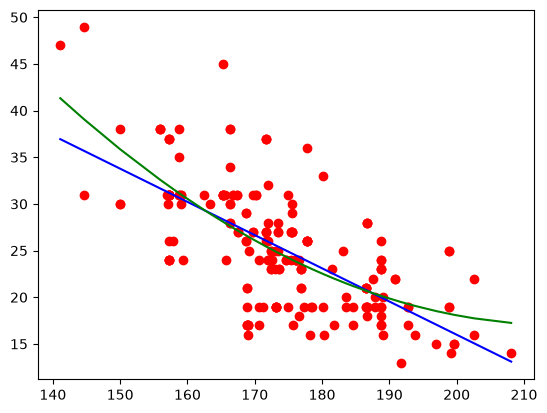

In [64]:
dataSorted = data.sort_values('length')
xLength = dataSorted['length']
yCityMPG = dataSorted['city-mpg']

plt.scatter(xLength, yCityMPG, color='red')
plt.plot(xLength, np.polyval(p1, xLength), color='blue')
plt.plot(xLength, np.polyval(p2, xLength), color='green')
plt.show()

Dla zmiennej length utworzyć jednowymiarowy estymator funkcji gęstości
Użyj:
scipy.stats.gaussian kde, proszę zwizualizować wynik przedstawiając jednocześnie próbki i funkcję gęstości. Do wykresu dodać legendę.
Użyj: (plot(..., label=’...’), legend)

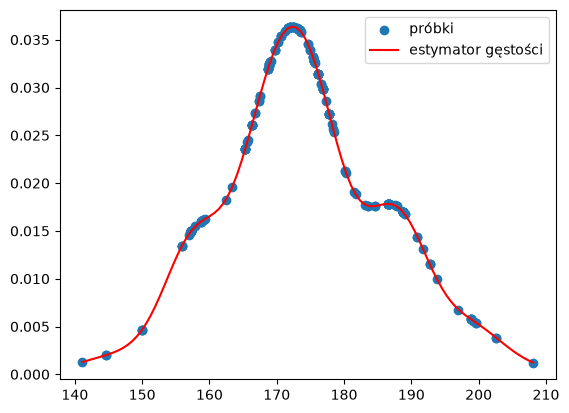

In [68]:
kde = gaussian_kde(xLength)
xVal = np.linspace(xLength.min(), xLength.max(), 100)
plt.scatter(xLength, kde(xLength), label='próbki')
plt.plot(xVal, kde(xVal), color='red', label='estymator gęstości')
plt.legend()
plt.show()

Utworzyć w jednym oknie graficznym dwa wykresy ax=subplot(...), ax.plot(...). Na drugim wykresie przedstawić analogicznie rozkład dla zmiennej ’width’.

/var/folders/jw/qgjltf4161z0ws29g_5gd54r0000gn/T/ipykernel_58242/1024337258.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  subplot.show()


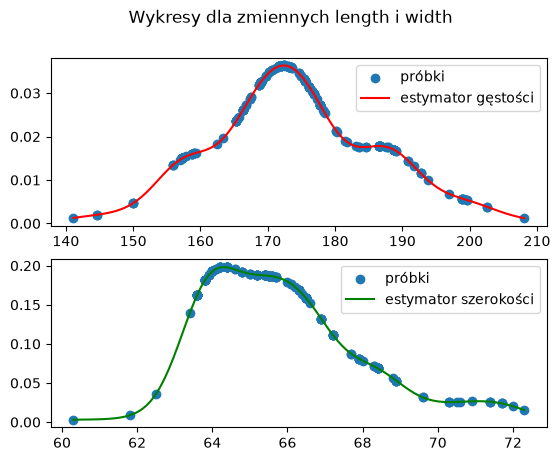

In [69]:
subplot, (plot1, plot2) = plt.subplots(2, 1)

plot1.scatter(xLength, kde(xLength), label='próbki')
plot1.plot(xVal, kde(xVal), color='red', label='estymator gęstości')
plot1.legend()

xWidth = data['width']
kdeWidth = gaussian_kde(xWidth)
xValWidth = np.linspace(xWidth.min(), xWidth.max(), 100)

plot2.scatter(xWidth, kdeWidth(xWidth), label='próbki')
plot2.plot(xValWidth, kdeWidth(xValWidth), color='green', label='estymator szerokości')
plot2.legend()

subplot.suptitle("Wykresy dla zmiennych length i width")
subplot.show()

Utworzyć dwuwymiarowy estymator funkcji gęstości dla zmiennych width i length , wynik przedstawić graficznie w nowym oknie rysując próbki poleceniem plot oraz funkcję gęstości używając polecenia meshgrid i contour.
Wynik zapisać do plików w formacie png i pdf (savefig)

/var/folders/jw/qgjltf4161z0ws29g_5gd54r0000gn/T/ipykernel_58242/1148364980.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


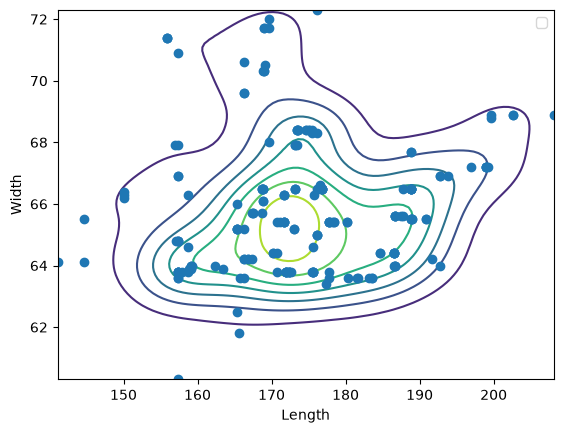

In [81]:
kde = gaussian_kde([xLength, xWidth])

X, Y = np.meshgrid(
    np.linspace(xLength.min(), xLength.max(), 100),
    np.linspace(xWidth.min(), xWidth.max(), 100)
)

# Wyplaszczenie X i Y (ravel), następnie utworzenie dwóch wierszy (vstack)
Z = kde(np.vstack([X.ravel(), Y.ravel()]))

# Powrót do 100x100
Z = Z.reshape(X.shape)

plt.contour(X, Y, Z)
plt.plot(xLength, xWidth, 'o')

plt.xlabel('Length')
plt.ylabel('Width')
plt.legend()

plt.savefig('wynik10.png')
plt.savefig('wynik10.pdf')

plt.show()